In [2]:
# =============================================================================
# CS-781 Phase 1 — Architecture #2: Gated Local-Global Persistent-Memory Transformer
#
# Inspired by (cited, not imported):
#   - Sliding-window local attention (Longformer, Beltagy et al. 2020)
#   - Persistent memory vectors added as extra K/V at every attention layer
#     (Sukhbaatar et al., "Augmenting Self-Attention with Persistent Memory", 2019)
#
# OUR OWN MODIFICATION (the thing that makes this not just a reimplementation):
#   Instead of concatenating local-window keys and memory keys into a single
#   softmax (what both source ideas do), each token computes TWO SEPARATE
#   attention outputs — one over its local window, one over persistent memory —
#   and a learned per-token sigmoid gate decides how much of each to use before
#   fusing. Rationale: legal sentences vary hugely in how much they depend on
#   long-range context (e.g. a citation back to a statute defined paragraphs
#   earlier) vs local syntax; an explicit learned gate lets the model decide
#   that mixing ratio per token, instead of leaving it to an implicit shared
#   softmax where local keys can numerically drown out a few relevant global ones.
#
# Differs from Architecture #1 (RMSNorm + RoPE + SwiGLU) in every major
# component: LayerNorm (not RMSNorm), learned relative positional bias
# (not RoPE), GELU MLP (not SwiGLU), and local+memory gated attention
# (not full causal self-attention).
#
# Run in Kaggle: paste each "# %%" block as its own cell.
# =============================================================================

In [1]:
# =============================================================================
# CS-781 Phase 1 — Architecture #2: Gated Local-Global Persistent-Memory Transformer
# CLEAN FINAL VERSION — all fixes applied:
#   - no gradient checkpointing (was causing ~20s/step; removed for speed)
#   - no DataParallel (Kaggle's dual-T4 NCCL setup failed; single GPU only)
#   - BATCH_SIZE=4, GRAD_ACCUM=8 (effective batch 32, fits in T4 memory)
#   - vectorized relative-position bias (no per-head Python loop)
#   - PYTORCH_CUDA_ALLOC_CONF set before any CUDA call
#   - reuses Architecture #1's tokenizer + pre-tokenized corpus (no re-download)
#
# Run in Kaggle: paste each "# %%" block as its own cell, in order, top to bottom.
# =============================================================================

# %% [1] Imports & HF login
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, math, random, time, zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("GPU count:", torch.cuda.device_count())  # informational only — we use 1 GPU

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Device: cuda
GPU count: 2


In [3]:
# %% [2] Config
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

# !!! EDIT THIS to the dataset slug Kaggle gave your committed Arch #1 notebook's output.
ARTIFACT_PATH = "/kaggle/input/datasets/akashmalgav/akashrm1"

BLOCK_SIZE = 1024
LOCAL_WINDOW = 256          # each token attends to at most this many previous real tokens
NUM_MEMORY = 32             # persistent memory slots (global, input-independent)
N_LAYER = 12
N_HEAD = 12
N_EMBD = 576                # -> keep params in 50M-300M range, verified below
FFN_MULT = 4                # standard (non-gated) GELU MLP
DROPOUT = 0.0
MAX_REL_DIST = LOCAL_WINDOW  # relative-position bias table range

BATCH_SIZE = 4               # fixed: was 8 (OOM), then 2 (too slow w/ GRAD_ACCUM=16)
GRAD_ACCUM = 8                # effective batch = 4*8 = 32
LR = 3e-4
MIN_LR = 3e-5
WARMUP_STEPS = 50
MAX_STEPS = 1000               # re-check timing at step 50 before committing to full run
EVAL_EVERY = 200
LOG_EVERY = 50

TARGET_GEN_WORDS = 128
MAX_GEN_TOKENS = 384
TEMPERATURE = 0.8
TOP_P = 0.95

OUTPUT_DIR = "/kaggle/working/cs781_phase1_arch2"
os.makedirs(OUTPUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(OUTPUT_DIR, "model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission_phase1_arch2.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")

In [4]:
# %% [3] Load the REUSED tokenizer + pre-tokenized corpus from Architecture #1
# (No re-download, no re-BPE-training, no re-tokenization of the 4 raw files.)
with open(f"{ARTIFACT_PATH}/legal_bpe.json", "r", encoding="utf-8") as f:
    _tok = json.load(f)
vocab = _tok["itos"]
merges = [tuple(p) for p in _tok["merges"]]
token_to_id = {tok: i for i, tok in enumerate(vocab)}
merges_rank = {p: i for i, p in enumerate(merges)}
PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
BOS_ID = token_to_id["<s>"]
EOS_ID = token_to_id["</s>"]
ACTUAL_VOCAB_SIZE = len(vocab)
EOW = "\u0100"

def word_to_symbols(word):
    return tuple(chr(b) for b in word.encode("utf-8", "ignore")) + (EOW,)

def bpe_encode_word(word):
    symbols = list(word_to_symbols(word))
    while len(symbols) > 1:
        pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        ranked = [(merges_rank[p], p) for p in pairs if p in merges_rank]
        if not ranked:
            break
        _, best = min(ranked)
        new_symbols, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == best[0] and symbols[i + 1] == best[1]:
                new_symbols.append(best[0] + best[1]); i += 2
            else:
                new_symbols.append(symbols[i]); i += 1
        symbols = new_symbols
    return symbols

def encode(text, add_bos=True, add_eos=True):
    ids = [BOS_ID] if add_bos else []
    for w in text.split():
        for sym in bpe_encode_word(w):
            ids.append(token_to_id.get(sym, UNK_ID))
    if add_eos:
        ids.append(EOS_ID)
    return ids

def decode(ids):
    byte_buf = []
    for i in ids:
        if i in (PAD_ID, BOS_ID, EOS_ID, UNK_ID):
            continue
        tok = vocab[i]
        for ch in tok:
            if ch == EOW:
                byte_buf.append(0x20)
            elif ord(ch) <= 255:
                byte_buf.append(ord(ch))
    return bytes(byte_buf).decode("utf-8", errors="replace").strip()

print("Loaded tokenizer. Vocab size:", ACTUAL_VOCAB_SIZE)
print("Sanity check:", decode(encode("The petitioner filed the present appeal.")))

train_tokens = torch.load(f"{ARTIFACT_PATH}/train_tokens.pt").tolist()
val_tokens = torch.load(f"{ARTIFACT_PATH}/val_tokens.pt").tolist()
print(f"Loaded pre-tokenized corpus: train={len(train_tokens):,} val={len(val_tokens):,}")

Loaded tokenizer. Vocab size: 32000
Sanity check: The petitioner filed the present appeal.
Loaded pre-tokenized corpus: train=60,000,000 val=1,066,512


In [5]:
# %% [4] Chunk into blocks for THIS architecture's BLOCK_SIZE
def make_blocks(tokens, block_size):
    n = (len(tokens) // block_size) * block_size
    tokens = tokens[:n]
    return torch.tensor(tokens, dtype=torch.long).view(-1, block_size)

train_blocks = make_blocks(train_tokens, BLOCK_SIZE)
val_blocks = make_blocks(val_tokens, BLOCK_SIZE)
print("Train blocks:", train_blocks.shape, "Val blocks:", val_blocks.shape)

class BlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return self.blocks.size(0)
    def __getitem__(self, idx):
        x = self.blocks[idx][:-1]
        y = self.blocks[idx][1:]
        return x, y

train_ds = BlockDataset(train_blocks)
val_ds = BlockDataset(val_blocks)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                           num_workers=2, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=True,
                         num_workers=2, pin_memory=True, persistent_workers=True)

Train blocks: torch.Size([58593, 1024]) Val blocks: torch.Size([1041, 1024])


In [6]:
# %% [5] Model: Gated Local-Global Persistent-Memory Transformer
# (no gradient checkpointing, no DataParallel — plain single-GPU forward)
class RelativePositionBias(nn.Module):
    """Learned scalar bias per (head, relative distance), T5-style but simple
    direct lookup table (distances clipped to [0, max_dist])."""
    def __init__(self, n_head, max_dist):
        super().__init__()
        self.max_dist = max_dist
        self.table = nn.Parameter(torch.zeros(n_head, max_dist + 1))

    def forward(self, window):
        dist = torch.arange(window, device=self.table.device).clamp(max=self.max_dist)
        return self.table[:, dist]  # (n_head, window)

class GatedLocalMemoryAttention(nn.Module):
    def __init__(self, n_embd, n_head, window, num_memory, max_rel_dist, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head
        self.window = window
        self.num_memory = num_memory

        self.q_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.k_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.v_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.out_proj = nn.Linear(n_embd, n_embd, bias=False)

        self.mem_k = nn.Parameter(torch.randn(n_head, num_memory, self.head_dim) * 0.02)
        self.mem_v = nn.Parameter(torch.randn(n_head, num_memory, self.head_dim) * 0.02)

        self.rel_bias = RelativePositionBias(n_head, max_rel_dist)
        self.gate_proj = nn.Linear(n_embd, n_head)
        self.dropout = dropout

    def forward(self, x):
        B, T, C = x.shape
        H, D = self.n_head, self.head_dim

        q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        k = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        v = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        idx = torch.arange(T, device=x.device)
        rel = idx[None, :] - idx[:, None]
        local_mask = (rel >= 0) & (rel < self.window)
        bias_table = self.rel_bias(self.window)
        rel_clamped = rel.clamp(min=0, max=self.window - 1)
        bias_full = bias_table[:, rel_clamped]
        neg_inf = torch.finfo(bias_full.dtype).min
        local_scores_base = torch.where(local_mask.unsqueeze(0), bias_full, torch.full_like(bias_full, neg_inf))

        attn_scores = torch.einsum("bhid,bhjd->bhij", q, k) / math.sqrt(D)
        attn_scores = attn_scores + local_scores_base[None, :, :, :]
        attn_probs = F.softmax(attn_scores, dim=-1)
        attn_probs = torch.nan_to_num(attn_probs)
        attn_probs = F.dropout(attn_probs, p=self.dropout, training=self.training)
        local_out = torch.einsum("bhij,bhjd->bhid", attn_probs, v)

        mem_k = self.mem_k.unsqueeze(0).expand(B, -1, -1, -1)
        mem_v = self.mem_v.unsqueeze(0).expand(B, -1, -1, -1)
        mem_scores = torch.einsum("bhid,bhmd->bhim", q, mem_k) / math.sqrt(D)
        mem_probs = F.softmax(mem_scores, dim=-1)
        mem_probs = F.dropout(mem_probs, p=self.dropout, training=self.training)
        mem_out = torch.einsum("bhim,bhmd->bhid", mem_probs, mem_v)

        gate = torch.sigmoid(self.gate_proj(x))
        gate = gate.transpose(1, 2).unsqueeze(-1)
        fused = gate * local_out + (1 - gate) * mem_out

        fused = fused.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(fused)

class MLP(nn.Module):
    def __init__(self, n_embd, mult, dropout):
        super().__init__()
        self.fc1 = nn.Linear(n_embd, mult * n_embd)
        self.fc2 = nn.Linear(mult * n_embd, n_embd)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.fc2(F.gelu(self.fc1(x))))

class Block(nn.Module):
    def __init__(self, n_embd, n_head, window, num_memory, max_rel_dist, ffn_mult, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = GatedLocalMemoryAttention(n_embd, n_head, window, num_memory, max_rel_dist, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = MLP(n_embd, ffn_mult, dropout)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

class GatedMemoryTransformer(nn.Module):
    def __init__(self, vocab_size, n_layer, n_head, n_embd, block_size,
                 window, num_memory, max_rel_dist, ffn_mult, dropout):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            Block(n_embd, n_head, window, num_memory, max_rel_dist, ffn_mult, dropout)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.tok_emb.weight = self.head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        x = self.drop(self.tok_emb(idx))
        for blk in self.blocks:
            x = blk(x)                       # plain forward — no checkpointing
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_p=0.95, eos_id=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p)
            cutoff[:, 1:] = cutoff[:, :-1].clone()
            cutoff[:, 0] = False
            sorted_probs[cutoff] = 0.0
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            idx = torch.cat([idx, next_id], dim=1)
            if eos_id is not None and (next_id == eos_id).all():
                break
        return idx

model = GatedMemoryTransformer(
    ACTUAL_VOCAB_SIZE, N_LAYER, N_HEAD, N_EMBD, BLOCK_SIZE,
    LOCAL_WINDOW, NUM_MEMORY, MAX_REL_DIST, FFN_MULT, DROPOUT
).to(device)
# NOTE: single GPU only — no DataParallel. Kaggle's dual-T4 NCCL setup
# failed (RuntimeError: NCCL Error 1: unhandled cuda error) when this was tried.
n_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {n_params/1e6:.2f}M parameters")
assert 50e6 <= n_params <= 300e6, "Model must be 50M-300M params — adjust N_LAYER/N_EMBD"

Model size: 66.83M parameters


In [7]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("Device name:", torch.cuda.get_device_name(0))
    print("Device:", torch.device("cuda"))

CUDA available: True
Device count: 2
Device name: Tesla T4
Device: cuda


In [8]:
# %% [6] Training loop (AdamW, cosine LR w/ warmup, grad accumulation, AMP)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    progress = min(progress, 1.0)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def evaluate():
    model.eval()
    losses = []
    for i, (x, y) in enumerate(val_loader):
        if i >= 50:
            break
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

history = {"step": [], "train_loss": [], "eval_step": [], "eval_loss": []}
step = 0
t0 = time.time()
model.train()
data_iter = iter(train_loader)

while step < MAX_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM):
        try:
            x, y = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            x, y = next(data_iter)
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(x, y)
            loss = loss / GRAD_ACCUM
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    lr = lr_at(step)
    for g in optimizer.param_groups:
        g["lr"] = lr
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()

    if step % LOG_EVERY == 0:
        elapsed = time.time() - t0
        print(f"step {step:5d} | loss {accum_loss:.4f} | lr {lr:.2e} | elapsed {elapsed/60:.1f}m")
        history["step"].append(step)
        history["train_loss"].append(accum_loss)
        # ---- quick sanity check at step 50: stop here mentally and judge timing ----
        # time_per_step = elapsed_minutes / step_count (after warmup noise settles)
        # total_hours_estimate = time_per_step * MAX_STEPS / 60

    if step % EVAL_EVERY == 0 and step > 0:
        val_loss = evaluate()
        ppl = math.exp(val_loss)
        print(f"  [eval] step {step} | val_loss {val_loss:.4f} | perplexity {ppl:.2f}")
        history["eval_step"].append(step)
        history["eval_loss"].append(val_loss)

    step += 1

final_val_loss = evaluate()
final_ppl = math.exp(final_val_loss)
print(f"FINAL val loss: {final_val_loss:.4f} | perplexity: {final_ppl:.4f}")

step     0 | loss 10.4373 | lr 0.00e+00 | elapsed 0.2m
step    50 | loss 6.9727 | lr 3.00e-04 | elapsed 9.4m
step   100 | loss 6.1078 | lr 2.98e-04 | elapsed 18.6m
step   150 | loss 5.4235 | lr 2.93e-04 | elapsed 27.9m
step   200 | loss 4.5425 | lr 2.84e-04 | elapsed 37.1m
  [eval] step 200 | val_loss 5.0435 | perplexity 155.01
step   250 | loss 4.3934 | lr 2.72e-04 | elapsed 46.5m
step   300 | loss 3.1693 | lr 2.56e-04 | elapsed 55.8m
step   350 | loss 1.8137 | lr 2.39e-04 | elapsed 65.0m
step   400 | loss 1.2902 | lr 2.19e-04 | elapsed 74.3m
  [eval] step 400 | val_loss 1.1676 | perplexity 3.21
step   450 | loss 0.8580 | lr 1.98e-04 | elapsed 83.7m
step   500 | loss 0.4861 | lr 1.76e-04 | elapsed 92.9m
step   550 | loss 0.4149 | lr 1.54e-04 | elapsed 102.1m
step   600 | loss 0.2583 | lr 1.32e-04 | elapsed 111.4m
  [eval] step 600 | val_loss 0.2892 | perplexity 1.34
step   650 | loss 0.2694 | lr 1.11e-04 | elapsed 120.8m
step   700 | loss 0.1534 | lr 9.12e-05 | elapsed 130.0m
step   7

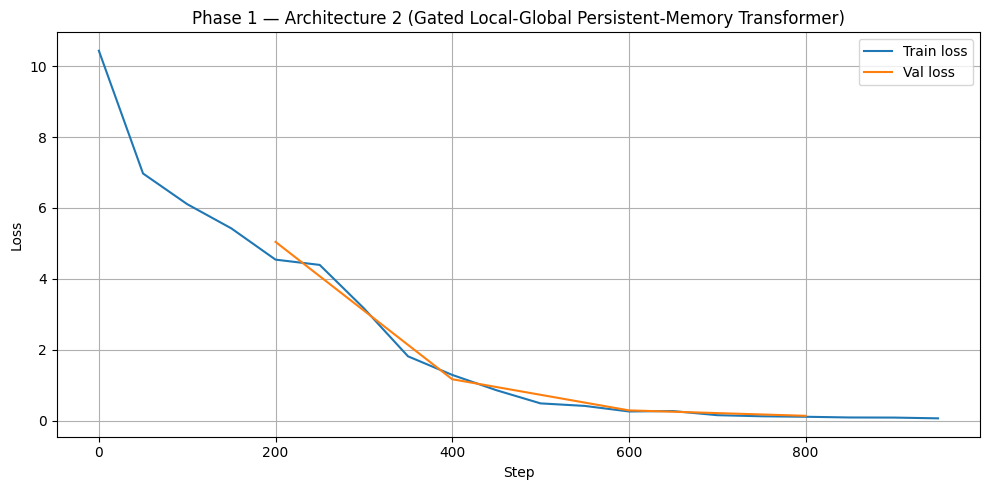

In [9]:
# %% [7] Plot loss  curve
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(history["step"], history["train_loss"], label="Train loss")
plt.plot(history["eval_step"], history["eval_loss"], label="Val loss")
plt.xlabel("Step"); plt.ylabel("Loss")
plt.title("Phase 1 — Architecture 2 (Gated Local-Global Persistent-Memory Transformer)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

In [10]:

# %% [8] Save checkpoint
torch.save({
    "model_state_dict": model.state_dict(),
    "config": dict(vocab_size=ACTUAL_VOCAB_SIZE, n_layer=N_LAYER, n_head=N_HEAD,
                   n_embd=N_EMBD, block_size=BLOCK_SIZE, window=LOCAL_WINDOW,
                   num_memory=NUM_MEMORY, max_rel_dist=MAX_REL_DIST,
                   ffn_mult=FFN_MULT, dropout=DROPOUT),
}, CKPT_PATH)
print("Saved checkpoint:", CKPT_PATH)

Saved checkpoint: /kaggle/working/cs781_phase1_arch2/model.pt


In [11]:
# %% [9] Generate 128-word continuations for the official test prompts
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN
)
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test examples:", len(test_data))

model.eval()
predictions = {}
MAX_PROMPT_TOKENS = BLOCK_SIZE - MAX_GEN_TOKENS

for i, (example_id, record) in enumerate(test_data.items()):
    prompt_ids = encode(record["text"], add_bos=True, add_eos=False)[:MAX_PROMPT_TOKENS]
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens=MAX_GEN_TOKENS,
                          temperature=TEMPERATURE, top_p=TOP_P, eos_id=EOS_ID)
    gen_ids = out[0, len(prompt_ids):].tolist()
    gen_text = decode(gen_ids)
    gen_words = gen_text.split()[:TARGET_GEN_WORDS]
    predictions[str(example_id)] = {"text": " ".join(gen_words)}
    if (i + 1) % 50 == 0:
        print(f"Generated {i+1}/{len(test_data)}")

# %% [10] Save prediction.json + zip for Codabench
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print("Codabench submission ready:", SUBMISSION_ZIP)

test.json: 0.00B [00:00, ?B/s]

Test examples: 1000
Generated 50/1000
Generated 100/1000
Generated 150/1000
Generated 200/1000
Generated 250/1000
Generated 300/1000
Generated 350/1000
Generated 400/1000
Generated 450/1000
Generated 500/1000
Generated 550/1000
Generated 600/1000
Generated 650/1000
Generated 700/1000
Generated 750/1000
Generated 800/1000
Generated 850/1000
Generated 900/1000
Generated 950/1000
Generated 1000/1000
Codabench submission ready: /kaggle/working/cs781_phase1_arch2/submission_phase1_arch2.zip
